C:\Users\tkjos\AppData\Local\Temp\ipykernel_26540\479010477.py:77: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


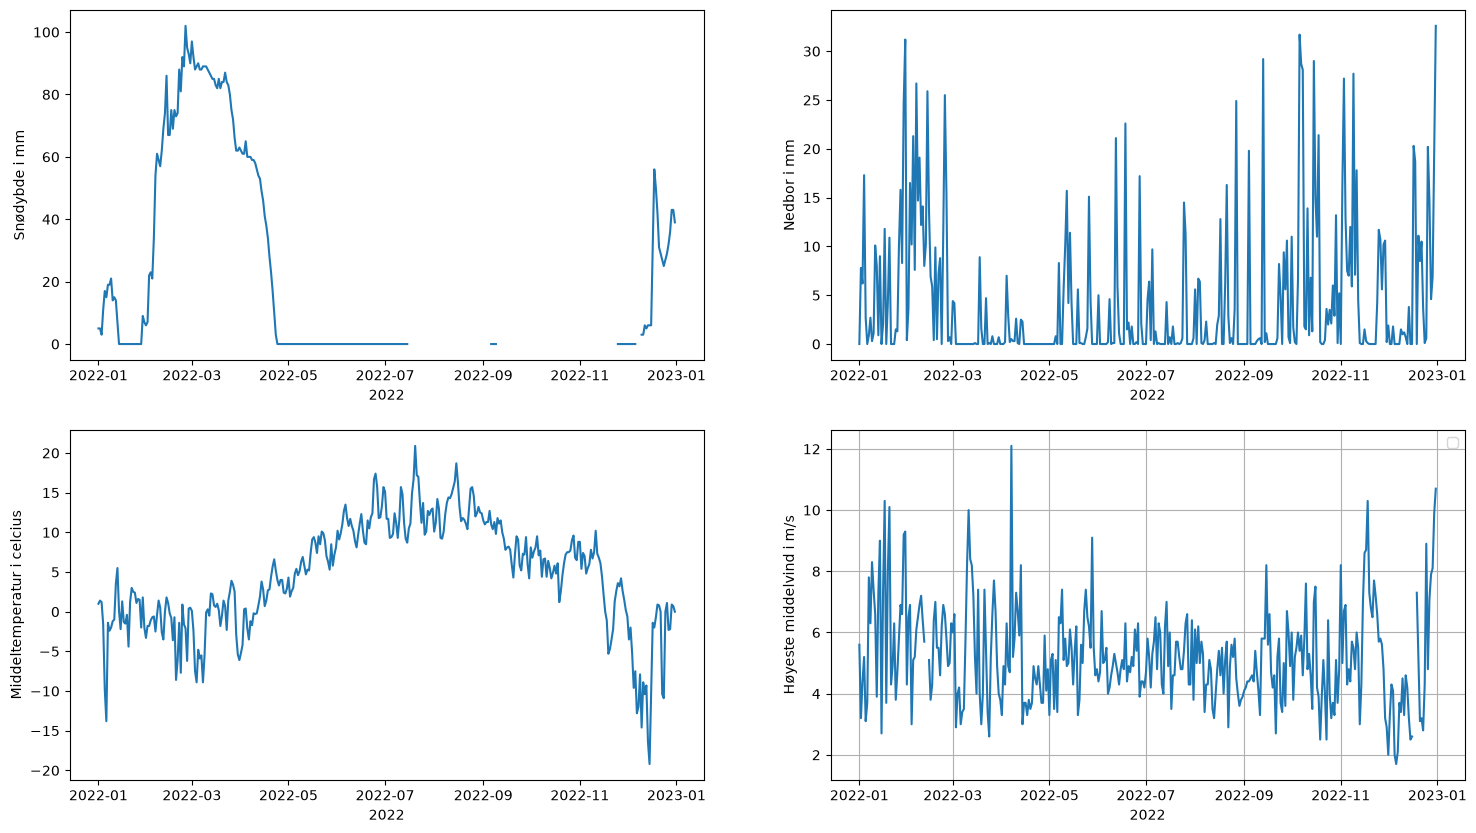

In [18]:
from datetime import datetime
import csv
import matplotlib.pyplot as plt

datoer = []
middeltemp = []
nedbor = []
vind = []
sno = []

år = int(input("Hvilket år vil du hente fra"))

with open("sinnes_2014_2025.csv", "r", encoding="utf-8") as f:
    reader = csv.reader(f, delimiter=';')
    next(reader)
    



    for rad in reader:
        try:
            d = datetime.strptime(rad[2], "%d.%m.%Y")
        except:
             continue
        
        def conv(x):
                    x = x.replace(",", ".")
                    return float(x) if x not in ["", "-"] else None
        
        datoer.append(d)
        middeltemp.append(conv(rad[3]))                         
        nedbor.append(conv(rad[4]))
        vind.append(conv(rad[5]))
        sno.append(conv(rad[6]))

def filter_år(år):
    dato_f = []
    temp_f = []
    nedbor_f = []
    vind_f = []
    sno_f = []

    for d, t, n, v, s in zip(datoer, middeltemp, nedbor, vind, sno):
        if d.year == år:
            dato_f.append(d)
            temp_f.append(t)
            nedbor_f.append(n)
            vind_f.append(v)
            sno_f.append(s)

    return dato_f, temp_f, nedbor_f, vind_f, sno_f

def plot_år(år):
    dato_f, temp_f, nedbor_f, vind_f, sno_f = filter_år(år)

    if not dato_f:
        print(f"Ingen målinger for {år}")
        return

    plt.figure(figsize=(18,10))
    plt.subplot(2,2,1)
    plt.plot(dato_f, sno_f)
    plt.xlabel(f"{år}")
    plt.ylabel("Snødybde i mm")
    plt.subplot(2,2,2)
    plt.plot(dato_f, nedbor_f)
    plt.xlabel(f"{år}")
    plt.ylabel("Nedbor i mm")
    plt.subplot(2,2,3)
    plt.plot(dato_f, temp_f)
    plt.xlabel(f"{år}")
    plt.ylabel("Middeltemperatur i celcius")
    plt.subplot(2,2,4)    
    plt.plot(dato_f, vind_f)
    plt.xlabel(f"{år}")
    plt.ylabel("Høyeste middelvind i m/s")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_år(år)

